#**3-Model Evaluation**

---
#**PART 1**
---

## 1. Dataset Loading and Distribution Ploting

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
import sklearn.preprocessing as preprocessing
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from scipy import stats

import sklearn.model_selection as model_selection
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.model_selection import cross_validate, StratifiedKFold

In [23]:
#import dataset
df = pd.read_csv('/content/sleep.csv')
display(df.head(),df.describe().T,df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


,count,mean,std,min,25%,50%,75%,max
age,8500.0,34.355647,11.584259,18.0,25.00,32.00,42.00,65.0
bedtime_phone_minutes,8500.0,59.250000,36.931991,1.0,31.00,51.00,79.00,180.0
screen_brightness_pct,8500.0,55.153882,19.850550,10.0,42.00,55.00,69.00,100.0
blue_light_filter_active,8500.0,0.467765,0.498989,0.0,0.00,0.00,1.00,1.0
caffeine_post_5pm_mg,8500.0,33.222471,51.935645,0.0,0.00,0.00,55.00,250.0
physical_activity_min,8500.0,35.701412,20.819390,0.0,21.00,35.00,50.00,112.0
sleep_latency_min,8500.0,40.671471,17.444914,6.0,28.20,37.60,49.70,123.3
total_sleep_hours,8500.0,6.266209,1.446258,3.2,5.24,6.33,7.35,9.8
deep_sleep_pct,8500.0,21.735741,3.069377,8.1,19.70,21.90,23.90,28.0
rem_sleep_pct,8500.0,19.105859,2.546459,9.6,17.40,19.10,20.80,27.0


None

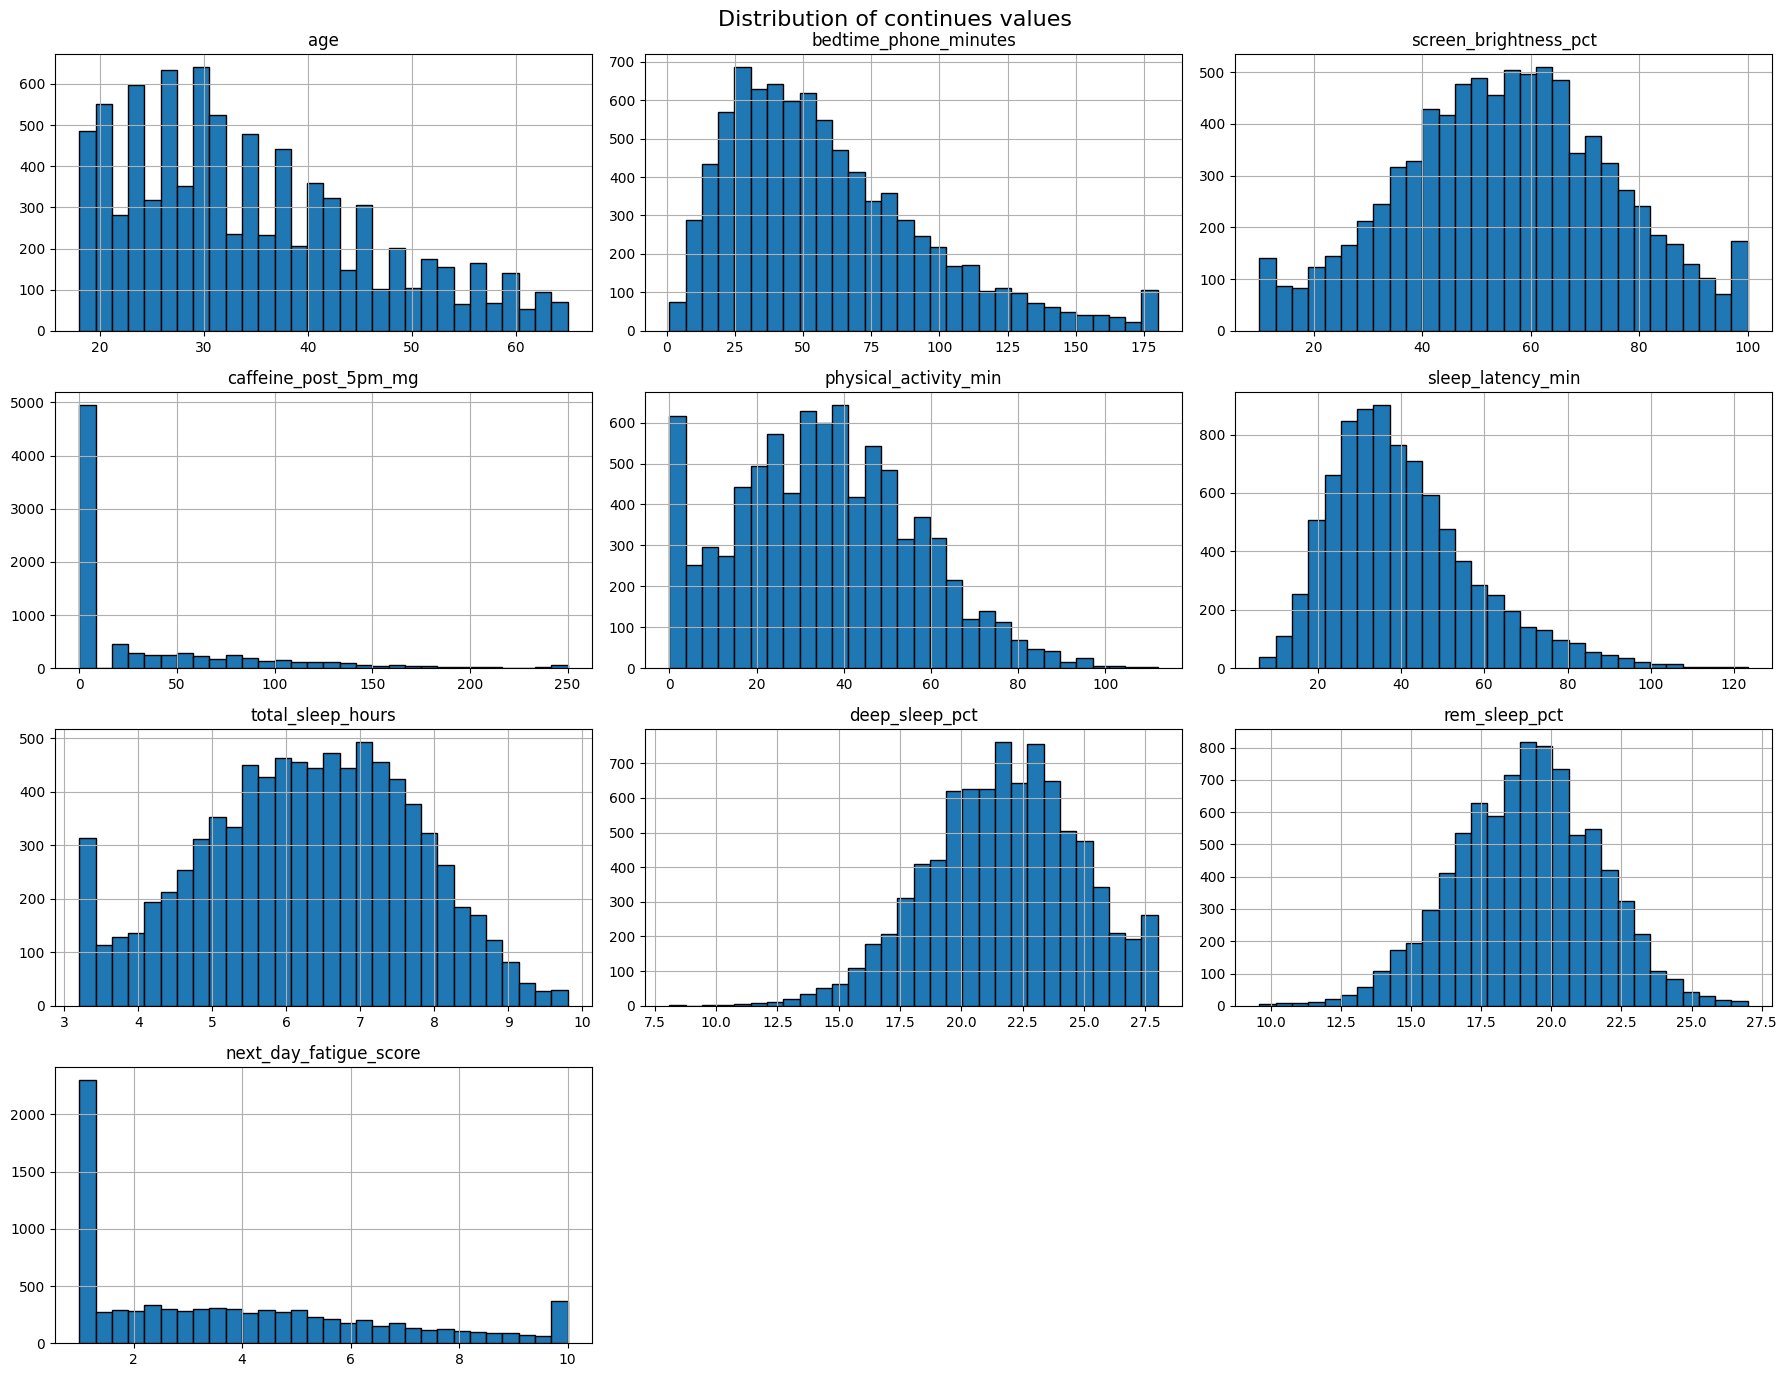

In [24]:
#Histogram for continues attributes (keeping numeric attributes and then removing discrete columns)

numeric_cols = df.select_dtypes(include=np.number).columns
continues_numeric_cols = numeric_cols.drop(['blue_light_filter_active', 'morning_alarm_snoozes']).tolist()


df[continues_numeric_cols].hist(bins=30,figsize=(18, 14),edgecolor='black')

plt.suptitle('Distribution of continues values', fontsize=16)
plt.tight_layout()

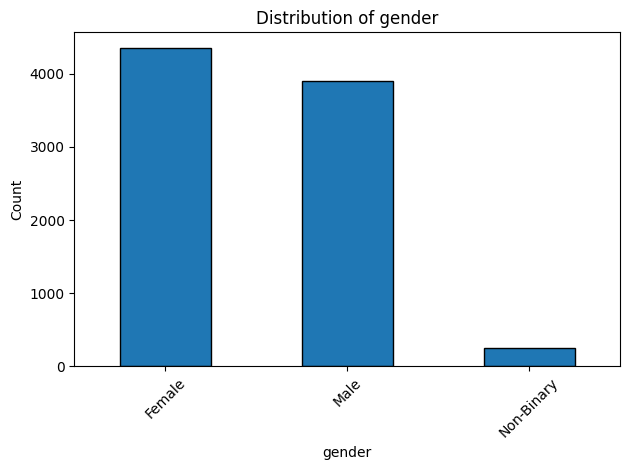

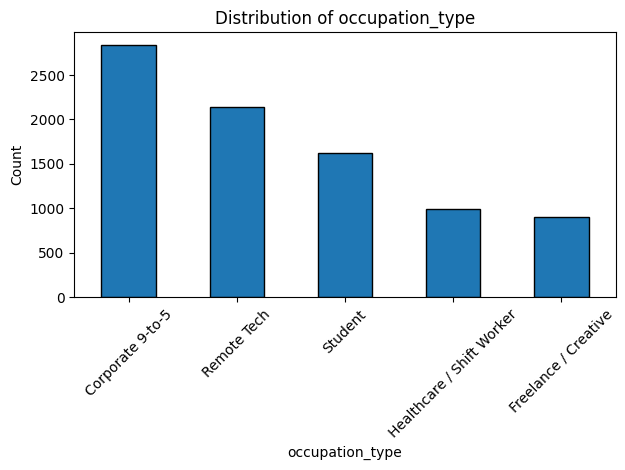

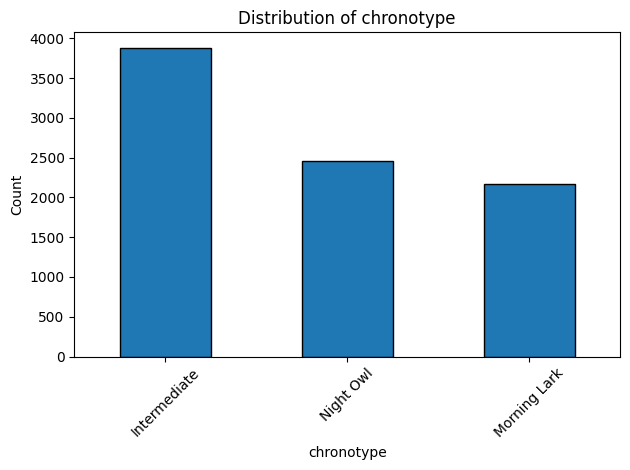

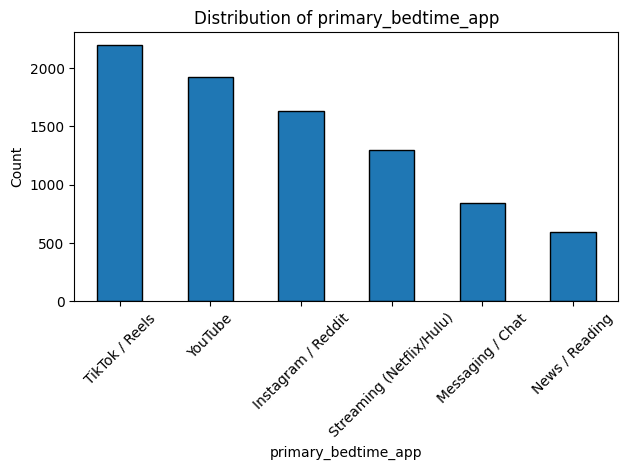

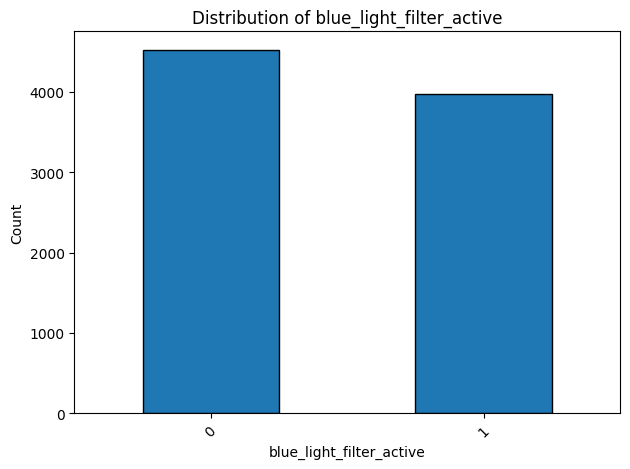

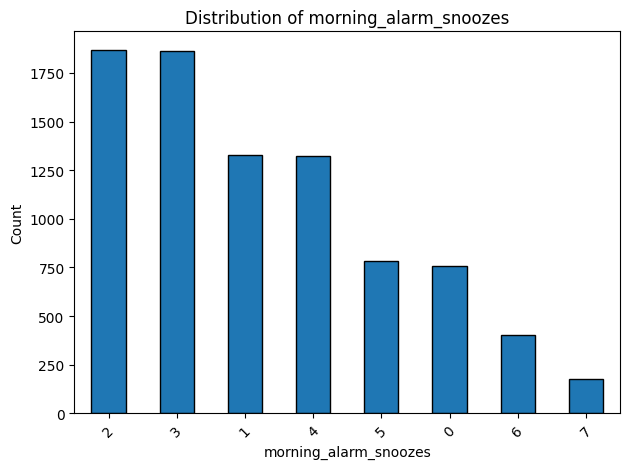

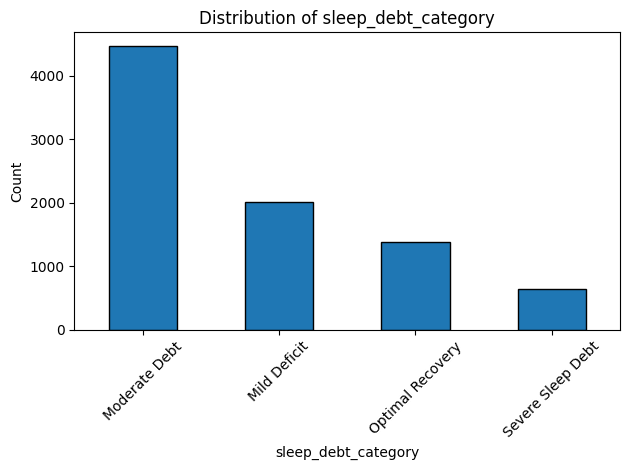

In [25]:
#Barplot for discrete and categorical values (removing continues values)
df =df.drop(columns = 'user_id')

categ_cols = df.drop(columns = continues_numeric_cols).columns



#Plot for every categorical attribute
for col in categ_cols:
  df[col].value_counts().plot(kind='bar', edgecolor='black')
  plt.title(f'Distribution of {col}')
  plt.xlabel(col)
  plt.ylabel('Count')
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()

### **Checking for imbalances(No, Medium, High):**
###**- High imbalance: noticed big difference between observations of the attribute's classes**
 ### -- sleep_debt_category(~ 53%, 23%, 17%, 7% ) , gender(~ 53%, 44%, 3%)
---
###**- Medium imbalance: noticed moderate difference between observations of the attribute's classes**
### -- morning_alarm_snoozes, primary_bedtime_app, chonotype, occupation_type,
---

###**- No imbalance: noticed very small difference between observations of the attribute's classes**
### -- blue_light_filter_active (~ 52%, 48%)

##2. Removing "next_day_fatigue_score"

In [26]:
df = df.drop(columns=['next_day_fatigue_score'])

##3. One-Hot encoding

In [27]:
# Encoding categorical columns
object_cols = ['gender','occupation_type', 'chronotype','primary_bedtime_app']

#Encoding process
encoder = OneHotEncoder(sparse_output=False)
encoded_data = encoder.fit_transform(df[object_cols])

#Creating new dataFrame
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(object_cols),index=df.index)

# Replacing original attributes with encoded
df = df.drop(columns=object_cols)
df = pd.concat([df, encoded_df], axis=1)

df.head()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


##4. Train-Test-Validation split

In [32]:
# Creating X & y
X = df.drop(columns = ['sleep_debt_category']).values
y = df['sleep_debt_category'].values

# First split 90-10 for Train-Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0, stratify=y)

# Second split on 70-20 for Train-Validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0, stratify=y_train)

#Displaying outcome for verification
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"X_val shape: {X_val.shape}")
print(f'Total: {X_train.shape[0] + X_test.shape[0] + X_val.shape[0]} rows')

X_train shape: (6120, 28)
X_test shape: (850, 28)
X_val shape: (1530, 28)
Total: 8500 rows


###5. KNN Training on train-val

In [35]:
#Checking square_root(N), because we always need  k = odd number

N = len(df)
square_N = int(N ** 0.5)

if (square_N % 2 == 0):
  square_N -= 1
print(square_N)

91


In [45]:
#Applying Z-Normalizaion for train-val
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# K & Weight definition
k_values = [3, 5, 15, 50, square_N]
weights = ['uniform', 'distance']


results_list = []

# 2. Double Loop iterating K for each weight
for weight in weights:
  for k in k_values:

        #KNN train
        knn = KNeighborsClassifier(n_neighbors=k, weights=weight)
        knn.fit(X_train_scaled, y_train)

        #KNN predictions for train-val
        y_train_pred = knn.predict(X_train_scaled)
        y_val_pred = knn.predict(X_val_scaled)

        #Metrics dictionary for train-val
        metrics = {
            'k': k,
            'weights': weight,
            'Train Acc': accuracy_score(y_train, y_train_pred),
            'Val Acc': accuracy_score(y_val, y_val_pred),
            'Train Precision': precision_score(y_train, y_train_pred, average='macro'),
            'Val Precision': precision_score(y_val, y_val_pred, average='macro'),
            'Train Recall': recall_score(y_train, y_train_pred, average='macro'),
            'Val Recall': recall_score(y_val, y_val_pred, average='macro'),
            'Train F1': f1_score(y_train, y_train_pred, average='macro'),
            'Val F1': f1_score(y_val, y_val_pred, average='macro'),
            'Train Balanced Acc': balanced_accuracy_score(y_train, y_train_pred),
            'Val Balanced Acc': balanced_accuracy_score(y_val, y_val_pred)
        }

        results_list.append(metrics)

# 3. Df creation with metrics
results1 = pd.DataFrame(results_list)
display(results1)


,k,weights,Train Acc,Val Acc,Train Precision,Val Precision,Train Recall,Val Recall,Train F1,Val F1,Train Balanced Acc,Val Balanced Acc
0,3,uniform,0.841993,0.704575,0.847288,0.678654,0.788198,0.624640,0.812043,0.646073,0.788198,0.624640
1,5,uniform,0.811275,0.714379,0.828076,0.719578,0.736756,0.620079,0.770554,0.654013,0.736756,0.620079
2,15,uniform,0.763235,0.728105,0.793873,0.752649,0.642320,0.602722,0.681614,0.641126,0.642320,0.602722
3,50,uniform,0.749020,0.750980,0.793212,0.786534,0.589880,0.604142,0.626881,0.643603,0.589880,0.604142
4,91,uniform,0.734477,0.742484,0.782081,0.781244,0.561880,0.574351,0.595929,0.610875,0.561880,0.574351
5,3,distance,1.000000,0.699346,1.000000,0.665590,1.000000,0.619888,1.000000,0.638758,1.000000,0.619888
6,5,distance,1.000000,0.707190,1.000000,0.696892,1.000000,0.615400,1.000000,0.643919,1.000000,0.615400
7,15,distance,1.000000,0.726144,1.000000,0.740117,1.000000,0.603657,1.000000,0.639093,1.000000,0.603657
8,50,distance,1.000000,0.743791,1.000000,0.779309,1.000000,0.600975,1.000000,0.641452,1.000000,0.600975
9,91,distance,1.000000,0.741830,1.000000,0.776956,1.000000,0.581637,1.000000,0.618804,1.000000,0.581637


###**Recall metric is the top priority for healthcare related data, with Balanced Accuracy playing important as well, role beacuse we have imbalaned classes.**

###**So,** *k=3 with uniform weight* **seems to be the best scenario based on Recall**

##6. Training on train-test with best scenario parameters

In [48]:
# Concatenting train-val and splitting train-test
X_train_val = np.concatenate((X_train, X_val), axis=0)
y_train_val = np.concatenate((y_train, y_val), axis=0)

#Applying Z-Normalizaion for train-test
scaler = StandardScaler()
X_train_val_scaled = scaler.fit_transform(X_train_val)
X_test_scaled = scaler.transform(X_test)

#Best Parameters
k=3
weight='uniform'

#KNN train
knn = KNeighborsClassifier(n_neighbors=k, weights=weight)
knn.fit(X_train_val_scaled, y_train_val)

#KNN predictions
y_train_val_pred = knn.predict(X_train_val_scaled)
y_test_pred = knn.predict(X_test_scaled)

#metrics
metrics = {
    'k': k,
    'weights': weight,
    'Train Recall': recall_score(y_train_val, y_train_val_pred, average = 'macro'),
    'Test Recall': recall_score(y_test, y_test_pred, average = 'macro'),
    'Train Balanced Acc': balanced_accuracy_score(y_train_val, y_train_val_pred),
    'Test Balanced Acc': balanced_accuracy_score(y_test, y_test_pred)
}

results_list2 = [metrics]

# Df creation with metrics
results2 = pd.DataFrame(results_list2)

#Comparison results1 vs results2
display(results2)
display(results1.head(1))


,k,weights,Train Recall,Test Recall,Train Balanced Acc,Test Balanced Acc
0,3,uniform,0.798675,0.621571,0.798675,0.621571


,k,weights,Train Acc,Val Acc,Train Precision,Val Precision,Train Recall,Val Recall,Train F1,Val F1,Train Balanced Acc,Val Balanced Acc
0,3,uniform,0.841993,0.704575,0.847288,0.678654,0.788198,0.62464,0.812043,0.646073,0.788198,0.62464


- ### **Balanced Acc: The model is balanced and generalizes well because Validation and Test have the same performance ~62%**

- ### **Overfitting: The model is a little bit overfitted 79% Train, 62% Test due to low k (k=3)**

- ### **Recall: Needs improvement because it catches only 62% of the total actual cases. We dont want to lose patients with disease.**

##7. Implementation with Cross Validation

In [53]:
#Creating folds
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Apply Z-Normalization
scaler_cv = StandardScaler()
X_train_val_scaled = scaler_cv.fit_transform(X_train_val)

# KNN Parameters
k_values = [3, 5, 15, 50, square_N]
weights_options = ['uniform', 'distance']

# Metrics
metrics = {
    'recall_macro': 'recall_macro',
    'balanced_accuracy': 'balanced_accuracy'
}

cv_results_list = []
raw_fold_scores = {} # To store raw scores of the best model for CI calculation

# Double Loop iterating K for each weight
for k in k_values:
    for weight in weights_options:
        knn_cv = KNeighborsClassifier(n_neighbors=k, weights=weight)

        # Executing Cross-Validation
        cv_scores = cross_validate(
            knn_cv, X_train_val_scaled, y_train_val,
            cv=folds, scoring=metrics, n_jobs=-1
        )

        # Metrics
        metrics_summary = {
            'k': k,
            'weights': weight,
            'CV Recall': np.mean(cv_scores['test_recall_macro']),
            'CV Balanced Acc': np.mean(cv_scores['test_balanced_accuracy'])
        }

        cv_results_list.append(metrics_summary)

        # Save raw array values temporarily tagged by key
        raw_fold_scores[f"{k}_{weight}"] = cv_scores

# Convert results to DataFrame
df_cv_results = pd.DataFrame(cv_results_list)
best_cv_row = df_cv_results.sort_values(by='CV Balanced Acc', ascending=False).iloc[0]

best_k = int(best_cv_row['k'])
best_weight = best_cv_row['weights']

print(f"Best CV Parameters found: k={best_k}, weights='{best_weight}'\n")

# Calculation of 95% Confidence
best_raw = raw_fold_scores[f"{best_k}_{best_weight}"]
ci_data = []

# Statistical Mapping for the 95% Confidence Interval using Student's t
for metric_key, score_name in [('test_recall_macro', 'Recall (Macro)'),
                               ('test_balanced_accuracy', 'Balanced Acc')]:

    scores = best_raw[metric_key]
    mean_score = np.mean(scores)

    # Calculate standard error of the mean (SEM)
    sem = stats.sem(scores)
    # Degrees of freedom (n - 1) where n = 5 folds
    df = len(scores) - 1
    # Multiplier for 95% confidence interval
    moe = stats.t.ppf(0.975, df) * sem

    ci_data.append({
        'Metric': score_name,
        'CV Mean Score': round(mean_score, 4),
        '95% Confidence Interval': f"[{round(mean_score - moe, 4)} , {round(mean_score + moe, 4)}]"
    })

# Display Confidence Intervals Table
df_ci = pd.DataFrame(ci_data)
display(df_ci)


Best CV Parameters found: k=3, weights='uniform'



,Metric,CV Mean Score,95% Confidence Interval
0,Recall (Macro),0.6174,"[0.6094 , 0.6254]"
1,Balanced Acc,0.6174,"[0.6094 , 0.6254]"


###**Implementation with CV shows the same best parameter result like before.**

##8. Double Cross Validation


In [61]:
# Creating a joined X & y
X_all = np.concatenate((X_train_val, X_test), axis=0)
y_all = np.concatenate((y_train_val, y_test), axis=0)

# Folds for each loop
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Parameters
square_N = int(np.sqrt(len(X_all)))
k_values = [3, 5, 15, 50, square_N]
weights_options = ['uniform', 'distance']

outer_recalls = []
outer_balanced_accs = []

from sklearn.metrics import recall_score, balanced_accuracy_score

# OUTER LOOP (3 Folds)
for outer_idx, (train_val_idx, test_idx) in enumerate(outer_cv.split(X_all, y_all)):
    X_train_val_fold, X_test_fold = X_all[train_val_idx], X_all[test_idx]
    y_train_val_fold, y_test_fold = y_all[train_val_idx], y_all[test_idx]

    best_inner_score = -1
    best_k = None
    best_weight = None

    # INNER LOOP (5 Folds)
    for k in k_values:
        for weight in weights_options:
            inner_scores = []

            # CV split
            for inner_train_idx, inner_val_idx in inner_cv.split(X_train_val_fold, y_train_val_fold):
                X_train_inner, X_val_inner = X_train_val_fold[inner_train_idx], X_train_val_fold[inner_val_idx]
                y_train_inner, y_val_inner = y_train_val_fold[inner_train_idx], y_train_val_fold[inner_val_idx]

                # Z-Normalization
                scaler_inner = StandardScaler()
                X_train_inner_scaled = scaler_inner.fit_transform(X_train_inner)
                X_val_inner_scaled = scaler_inner.transform(X_val_inner)

                # KNN Training
                knn_inner = KNeighborsClassifier(n_neighbors=k, weights=weight)
                knn_inner.fit(X_train_inner_scaled, y_train_inner)

                # Evaluation
                pred_inner = knn_inner.predict(X_val_inner_scaled)
                inner_bal_score = balanced_accuracy_score(y_val_inner, pred_inner)
                inner_rec_score = recall_score(y_val_inner, pred_inner, average='macro')

                # Concatenating scores
                scores = inner_bal_score + inner_rec_score
                inner_scores.append(scores)

            # Mean value calculation
            mean_inner_score = np.mean(inner_scores)
            if mean_inner_score > best_inner_score:
                best_inner_score = mean_inner_score
                best_k = k
                best_weight = weight

    print(f"Outer Fold {outer_idx + 1}: Best Params -> k={best_k}, weights='{best_weight}' (Inner Sum Score: {best_inner_score:.4f})")

    # Evaluation for outer
    scaler_outer = StandardScaler()
    X_train_val_fold_scaled = scaler_outer.fit_transform(X_train_val_fold)
    X_test_fold_scaled = scaler_outer.transform(X_test_fold)

    knn_outer = KNeighborsClassifier(n_neighbors=best_k, weights=best_weight)
    knn_outer.fit(X_train_val_fold_scaled, y_train_val_fold)

    y_outer_pred = knn_outer.predict(X_test_fold_scaled)

    # Metrics for outer fold
    outer_recalls.append(recall_score(y_test_fold, y_outer_pred, average='macro'))
    outer_balanced_accs.append(balanced_accuracy_score(y_test_fold, y_outer_pred))

# DataFrame Creation
nested_metrics = {
    'Metric': ['Recall (Macro)', 'Balanced Accuracy'],
    'Mean Value': [np.mean(outer_recalls), np.mean(outer_balanced_accs)]
    }

df_nested_results = pd.DataFrame(nested_metrics)
print("\n=== Final Results for NESTED CV ===")
display(df_nested_results.round(4))


Outer Fold 1: Best Params -> k=5, weights='distance' (Inner Sum Score: 1.1818)
Outer Fold 2: Best Params -> k=3, weights='uniform' (Inner Sum Score: 1.2276)
Outer Fold 3: Best Params -> k=3, weights='uniform' (Inner Sum Score: 1.2024)

=== Final Results for NESTED CV ===


,Metric,Mean Value
0,Recall (Macro),0.6164
1,Balanced Accuracy,0.6164


---
#**PART 2**
---

##**Implementing only train-test split without CV & Nested CV**

In [78]:
#Importing Dataset and Removing "sleep_dept_category"
df2 = pd.read_csv('/content/sleep.csv')
df2 = df2.drop(columns=['user_id', 'sleep_debt_category'])

print(df2.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       8500 non-null   int64  
 1   gender                    8500 non-null   object 
 2   occupation_type           8500 non-null   object 
 3   chronotype                8500 non-null   object 
 4   bedtime_phone_minutes     8500 non-null   int64  
 5   primary_bedtime_app       8500 non-null   object 
 6   screen_brightness_pct     8500 non-null   int64  
 7   blue_light_filter_active  8500 non-null   int64  
 8   caffeine_post_5pm_mg      8500 non-null   int64  
 9   physical_activity_min     8500 non-null   int64  
 10  sleep_latency_min         8500 non-null   float64
 11  total_sleep_hours         8500 non-null   float64
 12  deep_sleep_pct            8500 non-null   float64
 13  rem_sleep_pct             8500 non-null   float64
 14  morning_

In [79]:
# Replacing original categorical columns in df2 with the encoded_df from Part 1
object_cols = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']

df2 = df2.drop(columns=object_cols)
df2 = pd.concat([df2, encoded_df], axis=1)

df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 29 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   age                                           8500 non-null   int64  
 1   bedtime_phone_minutes                         8500 non-null   int64  
 2   screen_brightness_pct                         8500 non-null   int64  
 3   blue_light_filter_active                      8500 non-null   int64  
 4   caffeine_post_5pm_mg                          8500 non-null   int64  
 5   physical_activity_min                         8500 non-null   int64  
 6   sleep_latency_min                             8500 non-null   float64
 7   total_sleep_hours                             8500 non-null   float64
 8   deep_sleep_pct                                8500 non-null   float64
 9   rem_sleep_pct                                 8500 non-null   f

In [82]:
# Creating X & y
X = df2.drop(columns = ['next_day_fatigue_score']).values
y = df2['next_day_fatigue_score'].values

# First split 90-10 for Train-Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0, stratify=y)

# Second split on 70-20 for Train-Validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0, stratify=y_train)

#Displaying outcome for verification
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"X_val shape: {X_val.shape}")
print(f'Total: {X_train.shape[0] + X_test.shape[0] + X_val.shape[0]} rows')

X_train shape: (6120, 28)
X_test shape: (850, 28)
X_val shape: (1530, 28)
Total: 8500 rows


In [87]:
#Applying Z-Normalizaion for train-val
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# K & Weight definition
k_values = [3, 5, 15, 50, square_N]
weights = ['uniform', 'distance']


results_list = []

# 2. Double Loop iterating K for each weight
for weight in weights:
  for k in k_values:

        #KNN train
        knn = KNeighborsRegressor(n_neighbors=k, weights=weight)
        knn.fit(X_train_scaled, y_train)

        #KNN predictions for train-val
        y_train_pred = knn.predict(X_train_scaled)
        y_val_pred = knn.predict(X_val_scaled)

        #Metrics dictionary for train-val
        metrics = {
            'k': k,
            'weights': weight,
            'Train R_Square': r2_score(y_train, y_train_pred),
            'Val R_Square': r2_score(y_val, y_val_pred),
            'Train MAE': mean_absolute_error(y_train, y_train_pred),
            'Val MAE': mean_absolute_error(y_val, y_val_pred),
            'Train RMSE': root_mean_squared_error(y_train, y_train_pred),
            'Val RMSE': root_mean_squared_error(y_val, y_val_pred),
        }

        results_list.append(metrics)

# 3. Df creation with metrics
results1 = pd.DataFrame(results_list)
display(results1)

,k,weights,Train R_Square,Val R_Square,Train MAE,Val MAE,Train RMSE,Val RMSE
0,3,uniform,0.894157,0.786993,6.357734e-01,0.904292,8.734565e-01,1.237802
1,5,uniform,0.872565,0.800833,7.174869e-01,0.886941,9.584204e-01,1.196914
2,15,uniform,0.838506,0.806804,8.409771e-01,0.913904,1.078920e+00,1.178834
3,50,uniform,0.814059,0.801064,9.253739e-01,0.954554,1.157708e+00,1.196220
4,92,uniform,0.798732,0.792039,9.702064e-01,0.979417,1.204477e+00,1.223053
5,3,distance,1.000000,0.791499,1.289506e-08,0.892856,4.251510e-08,1.224639
6,5,distance,1.000000,0.805760,2.251888e-08,0.872772,7.230999e-08,1.182016
7,15,distance,1.000000,0.812552,6.626200e-08,0.897654,2.051332e-07,1.161165
8,50,distance,1.000000,0.805666,2.024154e-07,0.941069,6.221994e-07,1.182303
9,92,distance,1.000000,0.796427,3.555594e-07,0.967304,1.086264e-06,1.210079
